In [1]:
%pip install qiskit
%pip install qiskit_aer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 97.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 91.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 104.2 MB/s eta 0:00:00


In [2]:
%matplotlib inline
import platform
from importlib.metadata import version
import math
import matplotlib.pyplot as plt
import numpy as np
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Operator, Statevector
from qiskit import transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

ATOL = 1e-10
plt.rcParams.update(
    {
        "figure.figsize": (8, 3.8),
        "font.size": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
print("Python", platform.python_version())
for package in ("qiskit", "numpy", "matplotlib"):
    print(package, version(package))

Python 3.13.16
qiskit 2.5.2
numpy 2.1.3
matplotlib 3.10.0


The code will be built by an encoding of a soduku puzzle if the soduku grid is nxn, then we need a max encodable number $n$ we will need $N = log_2(n)$ qubits for this it will be built with E*N + E + 1 qubits where N is the number of qubits and E is the number of empty cells. Each set of N qubits will represent an empty cell. The $+E$ term is from the "flag" qubits we will need to build a proper oracle and the $+1$ is for the one ancilla required by Grover's algorithm. The details of this oracle is the most interesting part of this project and will be presented later.

$$
|\psi\rangle \;=\;
\overbrace{
  \underbrace{|q_1 q_2 \cdots q_N\rangle}_{\text{cell } 1\;(N \text{ qubits})}
  \otimes
  \underbrace{|q_{N+1} \cdots q_{2N}\rangle}_{\text{cell } 2\;(N \text{ qubits})}
  \otimes \cdots \otimes
  \underbrace{|q_{(E-1)N+1} \cdots q_{EN}\rangle}_{\text{cell } E\;(N \text{ qubits})}
}^{E \text{ cells} \,=\, EN \text{ qubits total}}
$$

(ignoring flag / ancillas)

We will use the following encoding scheme

$$
x=\sum_{j=0}^{n-1}2^jx_j + 1
$$

In [3]:
#general encoding (copied from gemini)
def int_to_custom_binary(n, num_bits=3):
    # Step 1: Shift to 0-indexed
    val = n - 1

    # Step 2: Calculate maximum allowed value for the given bits
    max_val = (1 << num_bits) - 1  # Equivalent to 2**num_bits - 1

    # Step 3: Check bounds and raise error if too high or too low
    if val > max_val:
        raise ValueError(f"Input {n} is too high to fit in {num_bits} bits (Max allowed: {max_val + 1})")
    if val < 0:
        raise ValueError("Input must be 1 or greater.")

    # Step 4: Format with dynamic bit width padding
    return f"{val:0{num_bits}b}"
def custom_binary_to_int(binary_str):
    # Step 1: Validate that the string only contains 0s and 1s
    if not all(char in '01' for char in binary_str):
        raise ValueError("Input string must contain only binary digits ('0' or '1').")

    # Step 2: Convert binary string back to a base-10 integer
    val = int(binary_str, 2)

    # Step 3: Shift back up to your 1-indexed format
    return val + 1

In [4]:
# encoding
def encode(x, N, ket = True):
  # take in list of integers and output the encoded states
  # using zig-zag encoding
  encoded = []
  for val in x:
    encoded.append(int_to_custom_binary(val, N))
  if ket:
    return "|" + "".join(encoded) + ">"
  else:
    return "".join(encoded)


In [5]:
# inverse of the encode function
def decode(bitstring, N):

  chunks = [bitstring[i:i+N] for i in range(0, len(bitstring), N)]
  return [custom_binary_to_int(c) for c in chunks]


checks that rows and coluns are full of unique values, basically valies that a solution is valid (copied from Google AI) we don't check boxes because the project wanted this to work for any N x N soduko.

In [6]:
# checks that rows and coluns are full of unique values, basically valies that
# a solution is valid (copied from Google AI)
# we don't check boxes because the project wanted this to work for any N soduko
# given boxes only form for some grids, we will neglect the box check

def verify_unique_matrix(matrix):
    n = len(matrix)
    if n == 0:
        return 1
    k = int(n ** 0.5)  # box size (3 for a 9x9 board)

    # Check each row for duplicates
    for row in matrix:
        if len(row) != len(set(row)):
            return 0

    # Check each column for duplicates
    for c in range(n):
        col = [matrix[r][c] for r in range(n)]
        if len(col) != len(set(col)):
            return 0

    # Check each k x k box for duplicates
    for br in range(0, n, k):
        for bc in range(0, n, k):
            box = [matrix[r][c]
                   for r in range(br, br + k)
                   for c in range(bc, bc + k)]
            if len(box) != len(set(box)):
                return 0

    return 1

We then make a function to find all the empty cells and then find all the numbers in the row / column of that empty value. These are the "forbidden values" or the values hat would lead to an invalid soduko. We will use this information to build the oracle.

**Additionally** I discovered that we also need to consider empty cells that may be in conflict with one anohter. We find these using the pairs function that I asked claude to make for me. We will also use these in making the oracle.

In [7]:
def find_empty_forbidden_values(board):
  forbidden_values = []
  empty_values = []
  for i in range(len(board)):
    for j in range(len(board)):
      if board[i,j] == 0:
        empty_values.append((i,j))

  # got this part from claude code. I had a weird bug and just gave it my code
  # and it gave me this.
  forbidden_values = {}
  n = len(board)

  k = int(n ** 0.5)

  for i, (r, c) in enumerate(empty_values):
      row_vals = {int(v) for v in board[r, :] if v != 0}
      col_vals = {int(v) for v in board[:, c] if v != 0}

      br, bc = k * (r // k), k * (c // k)
      box_vals = {int(v) for v in board[br:br + k, bc:bc + k].flatten() if v != 0}

      forbidden_values[i] = row_vals | col_vals | box_vals

  return forbidden_values, empty_values

# returns which qubit pairs cannot equal one another
def find_empty_pairs(empty_values, k):
  pairs = []
  for a in range(len(empty_values)):
    for b in range(a + 1, len(empty_values)):
      (r1, c1), (r2, c2) = empty_values[a], empty_values[b]
      if r1 == r2 or c1 == c2 or (r1 // k == r2 // k and c1 // k == c2 // k):
        pairs.append((a, b))
  return pairs

Quick Function checks

In [8]:
# 0 values indicate an empty block

qbits_per_cell = 2

board = np.array([[1,2,3,4],
 [3,0,2,1],
 [2,1,4,3],
 [4,3,0,0]])

# Find the empty values in the current board
forbidden_values, empty_values = find_empty_forbidden_values(board)

pairs = find_empty_pairs(empty_values, qbits_per_cell)

print(forbidden_values)
print(empty_values)
print(pairs)

x = [1,2,2,3]
print(encode(x, 2))
print(decode(encode(x, 2, False),2))


{0: {1, 2, 3}, 1: {2, 3, 4}, 2: {1, 3, 4}}
[(1, 1), (3, 2), (3, 3)]
[(1, 2)]
|00010110>
[1, 2, 2, 3]


In [9]:
# We now have the forbidden values for each qubit,
# we can use this to construct the oracle.

print(forbidden_values)
encode(list(forbidden_values[0]),2, False)

{0: {1, 2, 3}, 1: {2, 3, 4}, 2: {1, 3, 4}}


'000110'

We now make the function that makes one step of the total oracle. The oracle works by checking if a wavefunction is equal to a bitstring that is a forbidden value for that board location. It therefore uses a combination of x gates and a multicontrolled x gate to flip one of the flags from 1 to 0 if it finds a forbidden value.

This is essentially a quantum version of:

```
if (bitstring == forbidden_value):
  flag = !flag
```
It does this for every bitstring. Each empty cell has its own flag and that is the only flag it can flip.





In [10]:
# this gate will check if the current state is equal to the number
# represented by the bitstring the not gates are applied to the 1s
# instead of 0s because you want it to return 0 if the numbers are equal
# and 1 if they are not since 1 represents a valid soduko

# Want the Flag qubits to flip if equal
def create_one_oracle_gate(e_register, flag, bitstring):
  qubits = list(e_register) + [flag]
  oracle = QuantumCircuit(qubits, name="U_f")
  for i, bit in enumerate(bitstring):
    if bit == "0":
      oracle.x(e_register[i])
  oracle.mcx(list(e_register), flag)
  for i, bit in enumerate(bitstring):
    if bit == "0":
      oracle.x(e_register[i])
  return oracle.to_gate()

# I added this later (from Claude, was running low on time (sorry)),
# basically runs a series of XOR operations on each pair qubit and then chekcs
# if they are the same using an mcx gate to flip the flag.
def create_pair_gate(N):
  qc = QuantumCircuit(2 * N + 1, name="pair")
  for t in range(N): qc.cx(t, N + t)                       # b := a XOR b
  qc.mcx(list(range(N, 2 * N)), 2 * N, ctrl_state=0)       # fires if all XOR bits are 0
  for t in range(N): qc.cx(t, N + t)                       # restore b
  return qc.to_gate()


This next function does four main things: 1. it makes all the checks for the forbidden values, this is just running create_one_oracle_gate for each forbidden bitstring. 2. It creates gates that checks if certain pairs are the same 3. It then flips or does not flip the ancilla based on the value of the flags after all the checks have been run. 4. It "uncomputes" the flag values. This is a necessary step. If the flags were left computed, they would entangle to the the main register qubits, inhibiting the diffusion process. In order to unconpute, you just run the same operations in reverse. This works for any reversable operation.

In [11]:
# next step will be to make an oracle gate for each forbidden number (bitstring)
# That is, make a create_one_oracle_gate for each number in the row / column
# all of these gates put together should then create our oracle.


# made with help of claude after debugging
def create_oracle(qregisters, flags, ancilla, forbidden_values, qbits_per_cell, pairs):
    E = len(forbidden_values)
    oracle_circuit = QuantumCircuit(qregisters, flags,[ancilla])

    # 1. build the comparison gates, but don't apply them yet; keep them in a list
    steps = []
    for cell, forbidden_set in forbidden_values.items():
        e_reg = qregisters[cell * qbits_per_cell:(cell + 1) * qbits_per_cell]
        for value in sorted(forbidden_set):
            bitstring = encode([value], qbits_per_cell, False)
            gate = create_one_oracle_gate(e_reg, flags[cell], bitstring)
            steps.append((gate, list(e_reg) + [flags[cell]]))

    pair_gate = create_pair_gate(qbits_per_cell)             #  NEW block
    for p, (a, b) in enumerate(pairs):
        a_reg = qregisters[a * qbits_per_cell:(a + 1) * qbits_per_cell]
        b_reg = qregisters[b * qbits_per_cell:(b + 1) * qbits_per_cell]
        steps.append((pair_gate, list(a_reg) + list(b_reg) + [flags[E + p]]))
    # 2. compute: flags start at 1, each clash flips its cell's flag to 0
    oracle_circuit.x(flags)
    for gate, qubits in steps:
        oracle_circuit.append(gate, qubits)

    # 3. the actual answer: fires only if every flag is 1 (every cell valid)
    oracle_circuit.mcx(list(flags), ancilla)

    # We have to uncompute to disentangle the flag and encoding qubits
    # So that the implicit measurement doesn't mess up the diffusion
    # 4. uncompute: the same steps in reverse order
    for gate, qubits in reversed(steps):
        oracle_circuit.append(gate, qubits)
    oracle_circuit.x(flags)

    return oracle_circuit.to_gate()




Check to make sure our oracle process looks correct.

In [12]:
# Main
qbits_per_cell = 2

e_vals = QuantumRegister(len(empty_values)*qbits_per_cell, "e")
flags = QuantumRegister(len(empty_values) + len(pairs), "flags")
a_registers = QuantumRegister(1, "a")
circuit = QuantumCircuit(e_vals, flags, a_registers, name="U_f")

oracle = create_oracle(e_vals, flags, a_registers[0], forbidden_values, qbits_per_cell, pairs)

circuit.append(oracle, circuit.qubits)   # gate acts on e qubits + ancilla, in that order
print(circuit.draw(output="text"))               # shows the oracle as one box
print(circuit.decompose().draw(output="text"))   # shows the inner X / MCX gates

         ┌──────────────┐
    e_0: ┤0             ├
         │              │
    e_1: ┤1             ├
         │              │
    e_2: ┤2             ├
         │              │
    e_3: ┤3             ├
         │              │
    e_4: ┤4             ├
         │              │
    e_5: ┤5  circuit-47 ├
         │              │
flags_0: ┤6             ├
         │              │
flags_1: ┤7             ├
         │              │
flags_2: ┤8             ├
         │              │
flags_3: ┤9             ├
         │              │
      a: ┤10            ├
         └──────────────┘
              ┌──────┐                ┌──────┐                ┌──────┐        »
    e_0: ─────┤0     ├────────────────┤0     ├────────────────┤0     ├────────»
              │      │                │      │                │      │        »
    e_1: ─────┤1     ├────────────────┤1     ├────────────────┤1     ├────────»
              │      │┌──────┐        │      │┌──────┐        │      │┌──────┐»
  

We make a diffusion gate based off of the lecture notes.

In [13]:
# Make diffuser
def diffuser(e_vals, flags, ancilla):
    d = QuantumCircuit(e_vals, flags,[ancilla], name="diffuser")
    d.h(e_vals)
    d.mcx(list(e_vals), ancilla, ctrl_state=0)   # open controls: fires on |00...0>
    d.h(e_vals)
    return d.to_gate()

Oracle completed !!!!

Now we just run Grover's. We can copy lots of code from the problem set.

100011


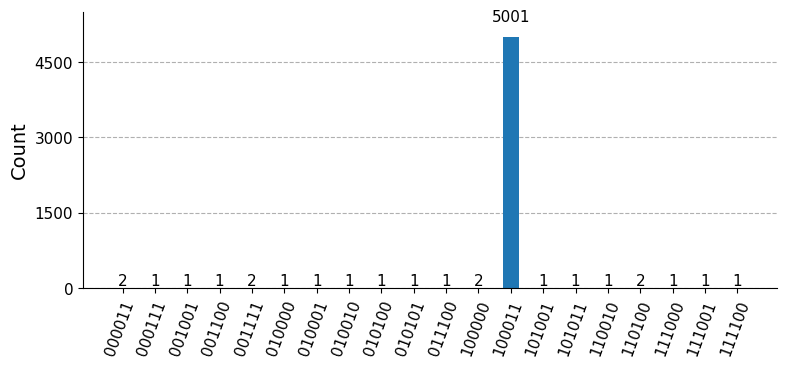

In [14]:
# prepare state

circuit = QuantumCircuit(e_vals, flags, a_registers, name="U_f")

circuit.h(e_vals)
circuit.x(a_registers)
circuit.h(a_registers)

n = len(e_vals)
N = 2**n
iterations = math.floor(math.pi / 4 * math.sqrt(N))

diff = diffuser(e_vals, flags, a_registers[0])
for _ in range(iterations):
    circuit.append(oracle, circuit.qubits)             # e qubits + ancilla
    circuit.append(diff, circuit.qubits)

c = ClassicalRegister(len(e_vals), "c")
circuit.add_register(c)
circuit.measure(e_vals, c)

tqc = transpile(circuit, AerSimulator())
counts = AerSimulator().run(tqc, shots=5024).result().get_counts()

best = max(counts, key=counts.get)
print(best)

plot_histogram(counts)


Take the answer and turn it back into a soduko.

In [15]:
answers = decode(best[::-1], qbits_per_cell)
for i, a in enumerate(answers):
  board[empty_values[i][0], empty_values[i][1]] = a

print(verify_unique_matrix(board))
print(board)


1
[[1 2 3 4]
 [3 4 2 1]
 [2 1 4 3]
 [4 3 1 2]]


The Classical check verifies the found answer is valid.

Plot Success Probability vs. Iterations

6


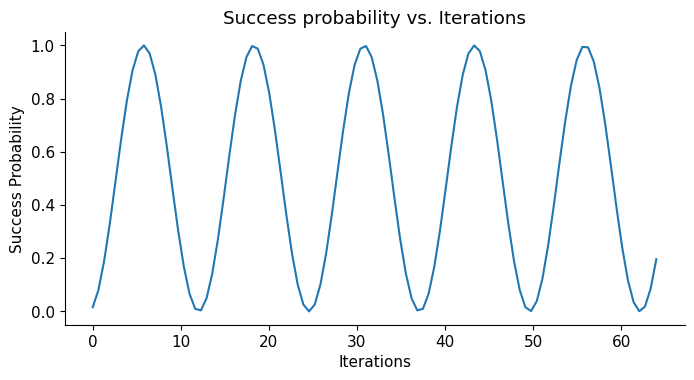

In [16]:
def success_fun(k,N):
  theta = np.asin(1/np.sqrt(N))
  return (np.sin((2*k+1)*theta))**2

k  = np.linspace(0,N,100)

y = success_fun(k,2**n)

plt.plot(k,y)
plt.xlabel("Iterations")
plt.ylabel("Success Probability")
plt.title("Success probability vs. Iterations")

print(iterations)

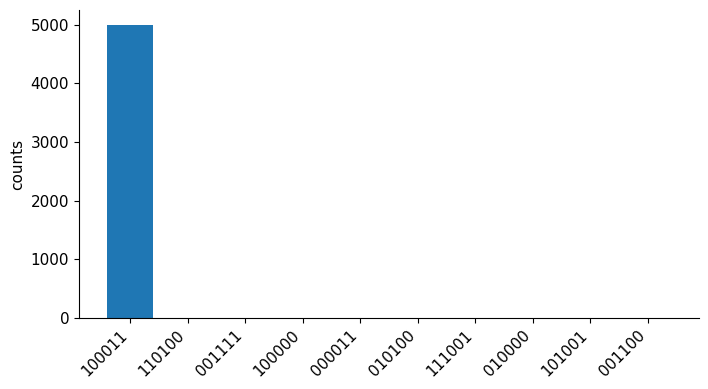

In [17]:


top = sorted(counts.items(), key=lambda kv: kv[1], reverse=True)[:10]
labels, values = zip(*top)

plt.figure(figsize=(8, 4))
plt.bar(labels, values)
plt.xticks(rotation=45, ha="right")
plt.ylabel("counts")
plt.show()